In [1]:
import torch
import torchvision

# check NVIDIA GPU available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [ ]:
# Set up image transforms, datasets, and data loaders

from pathlib import Path
from datasets import load_dataset
from torch.utils.data import DataLoader

from preprocessing import preprocess

batch_size = 32

train = load_dataset("Rajarshi-Roy-research/Defactify_Image_Dataset", split="train").with_transform(preprocess)
val = load_dataset("Rajarshi-Roy-research/Defactify_Image_Dataset", split="validation").with_transform(preprocess)
test = load_dataset("Rajarshi-Roy-research/Defactify_Image_Dataset", split="test").with_transform(preprocess)

trainloader = DataLoader(train, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True)
valloader = DataLoader(val, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)
testloader = DataLoader(test, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)


ImportError: attempted relative import with no known parent package

In [3]:
# Set up model for transfer learning

import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

model = resnet50(weights=ResNet50_Weights.DEFAULT)

# Replace the final layer with a new one that has 2 output classes
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 2)

for name, parameter in model.named_parameters():
    parameter.requires_grad = name.startswith(
        ("layer3.", "layer4.", "fc.")
    )

model.to(device)


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

In [4]:
# set up optimizer

import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam([
    {"params": model.layer3.parameters(), "lr": 1e-5},
    {"params": model.layer4.parameters(), "lr": 1e-5},
    {"params": model.fc.parameters(), "lr": 1e-4},
])

In [ ]:
# Train/eval loop
from sklearn.metrics import f1_score

best_f1 = float('-inf')
miss_count = 0
max_misses = 5

for epoch in range(50):
    model.train()
    for module in model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()


    running_loss = 0.0

    for i, batch in enumerate(trainloader, 0):
        images = batch["Image"].to(device)
        binary_labels = batch["Label_A"].to(device)
        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, binary_labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        if i % 200 == 199:    # print every 200 mini-batches
            print(f'[{epoch + 1}, {i + 1:5d}] loss: {running_loss / 200:.6f}')
            running_loss = 0.0
    print(f'Finished epoch {epoch + 1}')
    
    # Validation
    model.eval()
    y_true, y_pred = [], []

    with torch.no_grad():
        for batch in valloader:
            images = batch["Image"].to(device)
            predictions = model(images).argmax(dim=1)

            y_true.extend(batch["Label_A"].tolist())
            y_pred.extend(predictions.tolist())

    val_f1 = f1_score(
        y_true, y_pred, average="weighted", zero_division=0
    )
    print(f"Validation weighted F1: {val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1 = val_f1
        miss_count = 0
        torch.save(model, "./models/ResNet50FineTuned.pth")
    else:
        miss_count += 1
        if miss_count >= max_misses:
            print("Weighted F1 stopped improving, stopping early.")
            break

print('Finished Training')

[1,    75] loss: 0.488
[1,   150] loss: 0.338
[1,   225] loss: 0.181
[1,   300] loss: 0.131
[1,   375] loss: 0.098
[1,   450] loss: 0.086
[1,   525] loss: 0.072
[1,   600] loss: 0.068
[1,   675] loss: 0.066
[1,   750] loss: 0.057
[1,   825] loss: 0.049
[1,   900] loss: 0.050
[1,   975] loss: 0.059
[1,  1050] loss: 0.047
[1,  1125] loss: 0.045
[1,  1200] loss: 0.056
[1,  1275] loss: 0.061
Finished epoch 1
Validation weighted F1: 0.9827
[2,    75] loss: 0.023
[2,   150] loss: 0.017
[2,   225] loss: 0.032
[2,   300] loss: 0.028
[2,   375] loss: 0.016
[2,   450] loss: 0.026
[2,   525] loss: 0.034
[2,   600] loss: 0.022
[2,   675] loss: 0.036
[2,   750] loss: 0.030
[2,   825] loss: 0.024
[2,   900] loss: 0.022
[2,   975] loss: 0.019
[2,  1050] loss: 0.019
[2,  1125] loss: 0.023
[2,  1200] loss: 0.018
[2,  1275] loss: 0.030
Finished epoch 2
Validation weighted F1: 0.9863
[3,    75] loss: 0.009
[3,   150] loss: 0.011
[3,   225] loss: 0.006
[3,   300] loss: 0.003
[3,   375] loss: 0.006
[3,   4

              precision    recall  f1-score   support

        Real      0.985     0.975     0.980      1500
AI-generated      0.995     0.997     0.996      7500

    accuracy                          0.993      9000
   macro avg      0.990     0.986     0.988      9000
weighted avg      0.993     0.993     0.993      9000

Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):
[[1462   38]
 [  23 7477]]
Balanced accuracy: 0.9858
Brier score (lower is better): 0.0057
Log loss (lower is better): 0.0368
ROC-AUC (higher is better): 0.9987


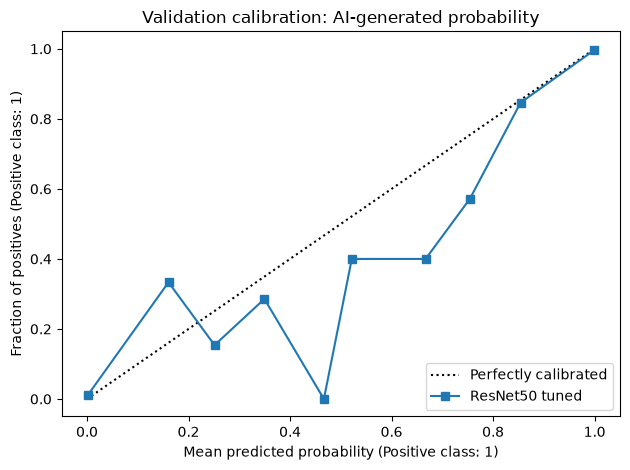

In [9]:
# Get detailed metrics for the current model on the validation set
model = torch.load('models/ResNet50FineTuned.pth', map_location=device, weights_only=False)

import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)

y_true, y_pred, y_ai_probability = [], [], []

model.eval()
with torch.no_grad():
    for batch in valloader:
        images = batch["Image"].to(device)
        outputs = model(images)
        probabilities = outputs.softmax(dim=1)
        predictions = probabilities.argmax(dim=1)

        y_true.extend(batch["Label_A"].to(device).tolist())
        y_pred.extend(predictions.tolist())
        # Class 1 is AI-generated; use its probability for every image.
        y_ai_probability.extend(probabilities[:, 1].tolist())

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Real", "AI-generated"],
    digits=3,
    zero_division=0,
))

print("Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))
print(f"Balanced accuracy: {balanced_accuracy_score(y_true, y_pred):.4f}")
print(f"Brier score (lower is better): {brier_score_loss(y_true, y_ai_probability):.4f}")
print(f"Log loss (lower is better): {log_loss(y_true, y_ai_probability, labels=[0, 1]):.4f}")
print(f"ROC-AUC (higher is better): {roc_auc_score(y_true, y_ai_probability):.4f}")

# Near the diagonal means predicted AI probabilities match observed AI frequencies.
CalibrationDisplay.from_predictions(
    y_true,
    y_ai_probability,
    n_bins=10,
    strategy="uniform",
    name="ResNet50 tuned",
)
plt.title("Validation calibration: AI-generated probability")
plt.tight_layout()
plt.show()


              precision    recall  f1-score   support

        Real      0.677     0.981     0.801      7500
AI-generated      0.996     0.906     0.949     37500

    accuracy                          0.919     45000
   macro avg      0.836     0.944     0.875     45000
weighted avg      0.943     0.919     0.924     45000

Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):
[[ 7360   140]
 [ 3515 33985]]
Balanced accuracy: 0.9438
Brier score (lower is better): 0.0737
Log loss (lower is better): 0.6116
ROC-AUC (higher is better): 0.9896


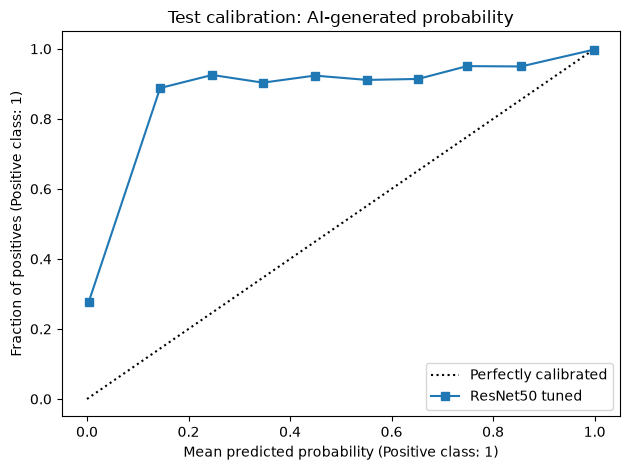

In [10]:
# Get detailed metrics for the final model on the test set
model = torch.load('models/ResNet50FineTuned.pth', map_location=device, weights_only=False)

import matplotlib.pyplot as plt
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    brier_score_loss,
    log_loss,
    roc_auc_score,
)

y_true, y_pred, y_ai_probability = [], [], []

model.eval()
with torch.no_grad():
    for batch in testloader:
        images = batch["Image"].to(device)
        outputs = model(images)
        probabilities = outputs.softmax(dim=1)
        predictions = probabilities.argmax(dim=1)

        y_true.extend(batch["Label_A"].to(device).tolist())
        y_pred.extend(predictions.tolist())
        # Class 1 is AI-generated; use its probability for every image.
        y_ai_probability.extend(probabilities[:, 1].tolist())

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["Real", "AI-generated"],
    digits=3,
    zero_division=0,
))

print("Confusion matrix (rows: actual, columns: predicted; order: Real, AI-generated):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))
print(f"Balanced accuracy: {balanced_accuracy_score(y_true, y_pred):.4f}")
print(f"Brier score (lower is better): {brier_score_loss(y_true, y_ai_probability):.4f}")
print(f"Log loss (lower is better): {log_loss(y_true, y_ai_probability, labels=[0, 1]):.4f}")
print(f"ROC-AUC (higher is better): {roc_auc_score(y_true, y_ai_probability):.4f}")

# Near the diagonal means predicted AI probabilities match observed AI frequencies.
CalibrationDisplay.from_predictions(
    y_true,
    y_ai_probability,
    n_bins=10,
    strategy="uniform",
    name="ResNet50 tuned",
)
plt.title("Test calibration: AI-generated probability")
plt.tight_layout()
plt.show()